In [6]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from hcipy import * 
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [21]:
#shoutout to joseph's mpl colorbars thing
def colorbar(mappable):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    import matplotlib.pyplot as plt
    last_axes = plt.gca()
    ax = mappable.axes
    fig = ax.figure
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)
    cbar = fig.colorbar(mappable, cax=cax)
    plt.sca(last_axes)
    return cbar

In [8]:
wavelength = 908E-9
bw = 126E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq,snr_threshold=2.6,speckle_window=60)

In [9]:
#import onsky datacube
cube = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/onsky_25b/fields/tau_ceti_adc_tests_offset_i.fits')

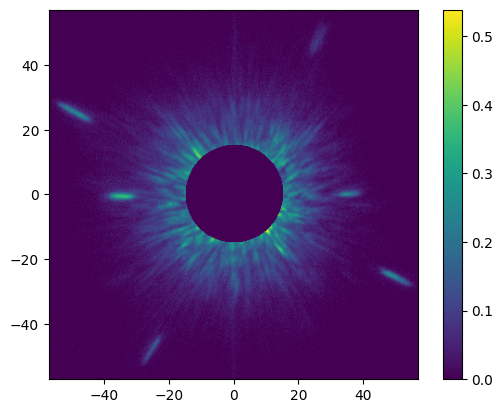

In [10]:
img = ADC.crop_image(cube[10],mask_diam=30)
img -= np.median(img)
img = Field([x if x>0 else 0 for x in img],img.grid)
imshow_field(img)
plt.colorbar()
plt.show()

In [11]:
#dispersion vector estimator
def est_mag_dir(psf,plotted=False):
    slopes = np.zeros(4)
    intercepts = np.zeros(4)
    points = []
    lines = np.zeros((4,3))

    for i in range(4):
        #print(ADC.slice_speckle_angle(psf,i,positions=True))
        try:
            angle,point = ADC.slice_speckle_angle(psf,i,positions=True)
        except:
            print(f'fitting not successful for speckle {i}')
            return np.nan
        if i == 0 or i ==2:
            angle = 90 - angle

        slope = np.tan(np.radians(angle))
        slopes[i] = slope
        points.append(point)
        intercepts[i] = -slope * point[0] + point[1]

    for j in range(4):
        lines[j,0] = slopes[j]
        lines[j,1] = -1
        lines[j,2] = points[j][1] - slopes[j]*points[j][0]

    A = lines[:,0]
    B = lines[:,1]
    C = lines[:,2]
    norm = np.sqrt(A**2 + B**2)

    A /= norm
    B /= norm
    C /= norm

    M = np.stack((A.T,B.T),axis=1)
    C = -C

    (x, y), *_ = np.linalg.lstsq(M, C)
    print(f'least-squares solution: ({x},{y})')
    magnitude_guess = np.sqrt(x**2+y**2) / 100

    #added logic for quadrants
    if x > 0 and y > 0: #i
        orientation_guess = np.degrees(np.atan(y/x))
    elif x < 0 and y >0: #ii
        orientation_guess = 180+np.degrees(np.atan(y/x))
    elif x < 0 and y < 0: #iii
        orientation_guess = -np.degrees(np.atan(y/x))
    else: #iv
        orientation_guess = -180-np.degrees(np.atan(y/x))

    print(f'Estimated dispersion direction {orientation_guess}°')
    print(f'Estimated dispersion magnitude {magnitude_guess}')

    if plotted:
        imshow_field(psf)
        a = np.array(psf.grid.x)

        for i in range(4):
            plt.plot(a, slopes[i] * a + intercepts[i],'w--',linewidth=0.5)

        plt.plot(x,y,'o',color='orange',label='dispersed speckle center')
        plt.plot(0,0,'o',color='red',label='psf center')

        plt.xlim((-60,60))
        plt.ylim((-60,60))
        #plt.legend(loc='upper right')
        
    return magnitude_guess,orientation_guess


least-squares solution: (2.787603617354546,-3.5081473662317437)
Estimated dispersion direction -128.47095137795884°
Estimated dispersion magnitude 0.04480829373083388


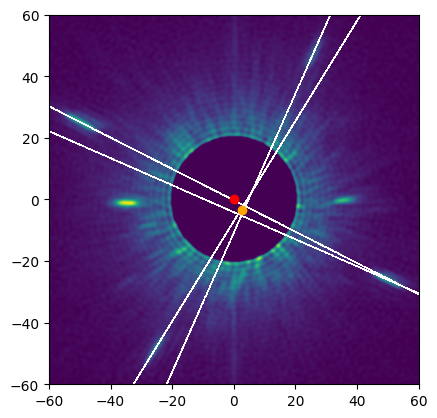

In [12]:
img_no = 101
img = ADC.filter_image(ADC.crop_image(cube[img_no],extent=512,mask_diam=40))
imshow_field(img)
h = est_mag_dir(img,plotted=True)

[ 23.88915687 -23.68913441  31.60745697 -26.97432229]
least-squares solution: (2.787603617354546,-3.5081473662317437)
Estimated dispersion direction -51.529048622041145


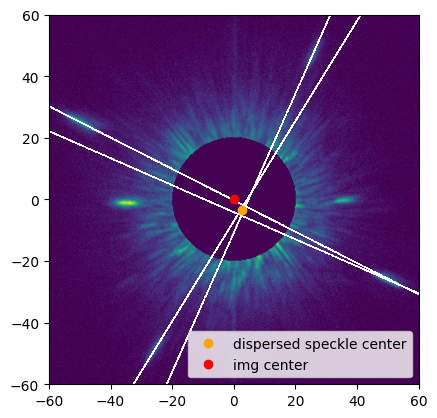

In [13]:
img_no = 101
img = ADC.filter_image(ADC.crop_image(cube[img_no],extent=512,mask_diam=40))

angs = ADC.all_speckle_angles(img)
print(angs)

#use a slope and a point on each of the speckles to do point-slope form and convert to y = mx + b form. 
angle1, point1 = ADC.slice_speckle_angle(img,0,positions=True)
angle1 = 90 - angle1
slope1_bef = np.tan(np.radians(angle1))
intercept1_bef = -slope1_bef * point1[0] + point1[1]

angle3, point3 = ADC.slice_speckle_angle(img,2,positions=True)
angle3 = 90 - angle3
slope3_bef = np.tan(np.radians(angle3))
intercept3_bef = -slope3_bef * point3[0] + point3[1]

angle2, point2 = ADC.slice_speckle_angle(img,1,positions=True)
slope2_bef = np.tan(np.radians(angle2))
intercept2_bef = -slope2_bef * point2[0] + point2[1]

angle4, point4 = ADC.slice_speckle_angle(img,3,positions=True)
slope4_bef = np.tan(np.radians(angle4))
intercept4_bef = -slope4_bef * point4[0] + point4[1]

#a,b,c coefficients
line1 = np.array([slope1_bef, -1, point1[1]-slope1_bef*point1[0]])
line2 = np.array([slope2_bef, -1, point2[1]-slope2_bef*point2[0]])
line3 = np.array([slope3_bef, -1, point3[1]-slope3_bef*point3[0]])
line4 = np.array([slope4_bef, -1, point4[1]-slope4_bef*point4[0]])

lines = np.stack((line1,line2,line3,line4))

A = lines[:,0]
B = lines[:,1]
C = lines[:,2]
norm = np.sqrt(A**2 + B**2)

A /= norm
B /= norm
C /= norm

M = np.stack((A.T,B.T),axis=1)
C = -C

(x, y), *_ = np.linalg.lstsq(M, C)
print(f'least-squares solution: ({x},{y})')
orientation_guess = np.atan(y/x)
print(f'Estimated dispersion direction {np.degrees(orientation_guess)}')

x_bef = x
y_bef = y

raw_bef = ADC.crop_image(cube[img_no],extent=512,mask_diam=40)
raw_bef -= np.median(raw_bef)
raw_bef = Field([x if x>0 else 0 for x in raw_bef],raw_bef.grid)
raw_bef = raw_bef / np.max(raw_bef)

plt.figure()
imshow_field(raw_bef)
a = np.array(img.grid.x)
plt.plot(a, slope1_bef * a + intercept1_bef,'w--',linewidth=0.5)
plt.plot(a, slope3_bef * a + intercept3_bef,'w--',linewidth=0.5)

plt.plot(a, slope2_bef * a + intercept2_bef,'w--',linewidth=0.5)
plt.plot(a, slope4_bef * a + intercept4_bef,'w--',linewidth=0.5)

plt.plot(x,y,'o',color='orange',label='dispersed speckle center')
plt.plot(0,0,'o',color='red',label='img center')

plt.xlim((-60,60))
plt.ylim((-60,60))
plt.legend(loc='lower right')
plt.show()

[ 24.91992332 -27.64350049  29.15004159 -24.01334167]
least-squares solution: (2.918557889469694,-0.45617862778420337)
Estimated dispersion direction -8.883609519263798


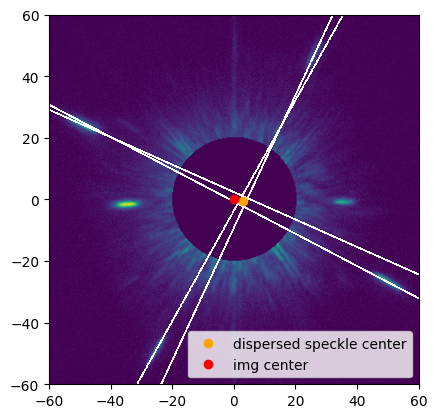

In [14]:
img_no = 2002
img = ADC.filter_image(ADC.crop_image(cube[img_no],extent=512,mask_diam=40))

angs = ADC.all_speckle_angles(img)
print(angs)

#use a slope and a point on each of the speckles to do point-slope form and convert to y = mx + b form. 
angle1, point1 = ADC.slice_speckle_angle(img,0,positions=True)
angle1 = 90 - angle1
slope1 = np.tan(np.radians(angle1))
intercept1 = -slope1 * point1[0] + point1[1]

angle3, point3 = ADC.slice_speckle_angle(img,2,positions=True)
angle3 = 90 - angle3
slope3 = np.tan(np.radians(angle3))
intercept3 = -slope3 * point3[0] + point3[1]

angle2, point2 = ADC.slice_speckle_angle(img,1,positions=True)
slope2 = np.tan(np.radians(angle2))
intercept2 = -slope2 * point2[0] + point2[1]

angle4, point4 = ADC.slice_speckle_angle(img,3,positions=True)
slope4 = np.tan(np.radians(angle4))
intercept4 = -slope4 * point4[0] + point4[1]

#a,b,c coefficients
line1 = np.array([slope1, -1, point1[1]-slope1*point1[0]])
line2 = np.array([slope2, -1, point2[1]-slope2*point2[0]])
line3 = np.array([slope3, -1, point3[1]-slope3*point3[0]])
line4 = np.array([slope4, -1, point4[1]-slope4*point4[0]])

lines = np.stack((line1,line2,line3,line4))

A = lines[:,0]
B = lines[:,1]
C = lines[:,2]
norm = np.sqrt(A**2 + B**2)

A /= norm
B /= norm
C /= norm

M = np.stack((A.T,B.T),axis=1)
C = -C

(x, y), *_ = np.linalg.lstsq(M, C)
print(f'least-squares solution: ({x},{y})')
orientation_guess = np.atan(y/x)
print(f'Estimated dispersion direction {np.degrees(orientation_guess)}')

raw = ADC.crop_image(cube[img_no],extent=512,mask_diam=40)
raw -= np.median(raw)
raw = Field([x if x>0 else 0 for x in raw],raw.grid)
raw = raw/np.max(raw)

plt.figure()
imshow_field(raw)
a = np.array(img.grid.x)
plt.plot(a, slope1 * a + intercept1,'w--',linewidth=0.5)
plt.plot(a, slope3 * a + intercept3,'w--',linewidth=0.5)

plt.plot(a, slope2 * a + intercept2,'w--',linewidth=0.5)
plt.plot(a, slope4 * a + intercept4,'w--',linewidth=0.5)

plt.plot(x,y,'o',color='orange',label='dispersed speckle center')
plt.plot(0,0,'o',color='red',label='img center')

plt.xlim((-60,60))
plt.ylim((-60,60))
plt.legend(loc='lower right')
plt.show()

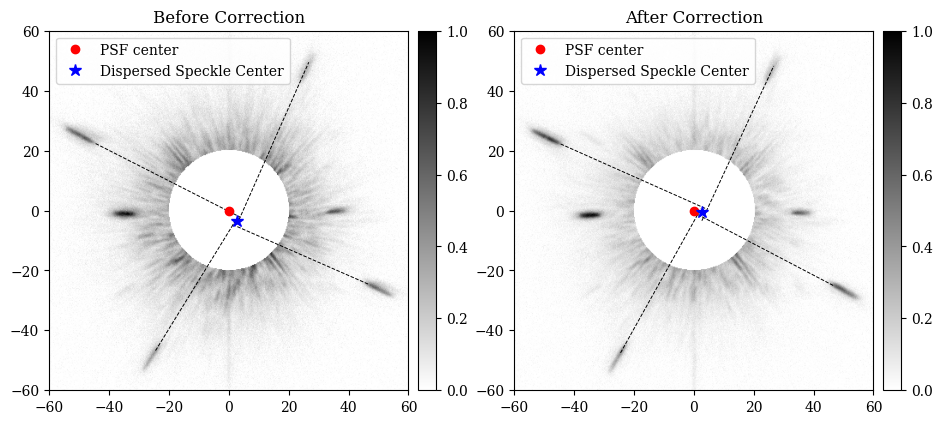

In [75]:
#now let's generate a pretty figure
plt.rcParams['font.family'] = 'serif'

fig, ax = plt.subplots(1,2,figsize=(11,5))
bf = imshow_field(raw_bef,ax=ax[0],cmap='binary')
af = imshow_field(raw,ax=ax[1],cmap='binary')

#figure params
ax[0].set_box_aspect(1)
ax[1].set_box_aspect(1)

ax[0].set_ylim((-60,60))
ax[0].set_xlim((-60,60))

ax[1].set_ylim((-60,60))
ax[1].set_xlim((-60,60))

ax[0].set_title('Before Correction')
ax[1].set_title('After Correction')

colorbar(bf)
colorbar(af)

#edit the a bounds so the line doesn't cover the speckle
a = a = np.array(raw.grid.x.reshape(raw.grid.shape)[0, :])
a1 = a[265:350]
a2 = a[170:265]
a3 = a[260:420]
a4 = a[100:270]

#lines on before image
ax[0].plot(a1, slope1_bef * a1 + intercept1_bef,'--',linewidth=0.7,color='black')
ax[0].plot(a2, slope3_bef * a2 + intercept3_bef,'--',linewidth=0.7,color='black')

ax[0].plot(a3, slope2_bef * a3 + intercept2_bef,'--',linewidth=0.7,color='black')
ax[0].plot(a4, slope4_bef * a4 + intercept4_bef,'--',linewidth=0.7,color='black')

ax[0].plot(0,0,'o',color='red',label='PSF center')
ax[0].plot(x_bef,y_bef,'*',color='blue',label='Dispersed Speckle Center',markersize=9)

#lines on after image
ax[1].plot(a1, slope1 * a1 + intercept1,'--',linewidth=0.7,color='black')
ax[1].plot(a2, slope3 * a2 + intercept3,'--',linewidth=0.7,color='black')

ax[1].plot(a3, slope2 * a3 + intercept2,'--',linewidth=0.7,color='black')
ax[1].plot(a4, slope4 * a4 + intercept4,'--',linewidth=0.7,color='black')

ax[1].plot(0,0,'o',color='red',label='PSF center')
ax[1].plot(x,y,'*',color='blue',label='Dispersed Speckle Center',markersize=9)

ax[0].legend()
ax[1].legend()
plt.show()